In [1]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
# sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar


%load_ext autoreload
%autoreload 2

# Load reference dataset for the simulation. These data were curated from CARD run on PDAC data

In [2]:
adata = ad.read_h5ad("../../Data/spatial.h5ad")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.filter_genes(adata, min_counts=1)

pd_B   = pd.read_csv('../../Data/B_with_genes.csv')
pd_B   = pd_B.set_index(pd_B.columns[0]).T

V_card = pd.read_csv('../../Data/CARD_Res_V.csv', index_col=0)

# Simulate a time course with cancer invasion and sinusoidal warping

In [3]:

(adata_list,
 V_true_temporal,
 cluster_labels_temporal,
 ref_adata_out,
 pd_B_out,
 warp_params) = create_realistic_data(
    ref_adata         = adata,
    pd_B              = pd_B,
    V_card            = V_card,
    n_time            = 5,
    cluster_dominants = [
        "Cancer_clone_A",
        "Cancer_clone_B",
        "Acinar_cells",
        "Ductal_terminal_ductal_like",
    ],
    cancer_types      = ["Cancer_clone_A", "Cancer_clone_B"],
    invasion_prob     = 0.3,
    extra_rotate_deg  = 20,
    warp_amplitude    = 0.03,
    negbinom_r = 1.0,
    seed = 666
)

  Spots: 428  |  Cell types: 20  |  Genes: 7050
  Clustering V into 4 regions via Leiden...
  Reconstructing V  (dom=0.5, sec=0.2, noise=0.3)
  Explicit dominants: ['Cancer_clone_A', 'Cancer_clone_B', 'Acinar_cells', 'Ductal_terminal_ductal_like']
    cluster 0: dominant=Acinar_cells, second=Ductal_CRISP3_high-centroacinar_like, n=84
    cluster 1: dominant=Cancer_clone_B, second=Ductal_CRISP3_high-centroacinar_like, n=152
    cluster 2: dominant=Ductal_terminal_ductal_like, second=Ductal_CRISP3_high-centroacinar_like, n=48
    cluster 3: dominant=Cancer_clone_A, second=Cancer_clone_B, n=144
  Cancer clusters  : [1, 3]  (invasion_prob=0.3)
  Target sparsity  : 0.923
  Calibrated lib_mean: 0.500
  t=0  cancer spots=296/428  V range [0.000, 0.500]
  t=1  cancer spots=324/428  V range [0.000, 0.500]
  t=2  cancer spots=349/428  V range [0.000, 0.500]
  t=3  cancer spots=366/428  V range [0.000, 0.500]
  t=4  cancer spots=380/428  V range [0.000, 0.500]


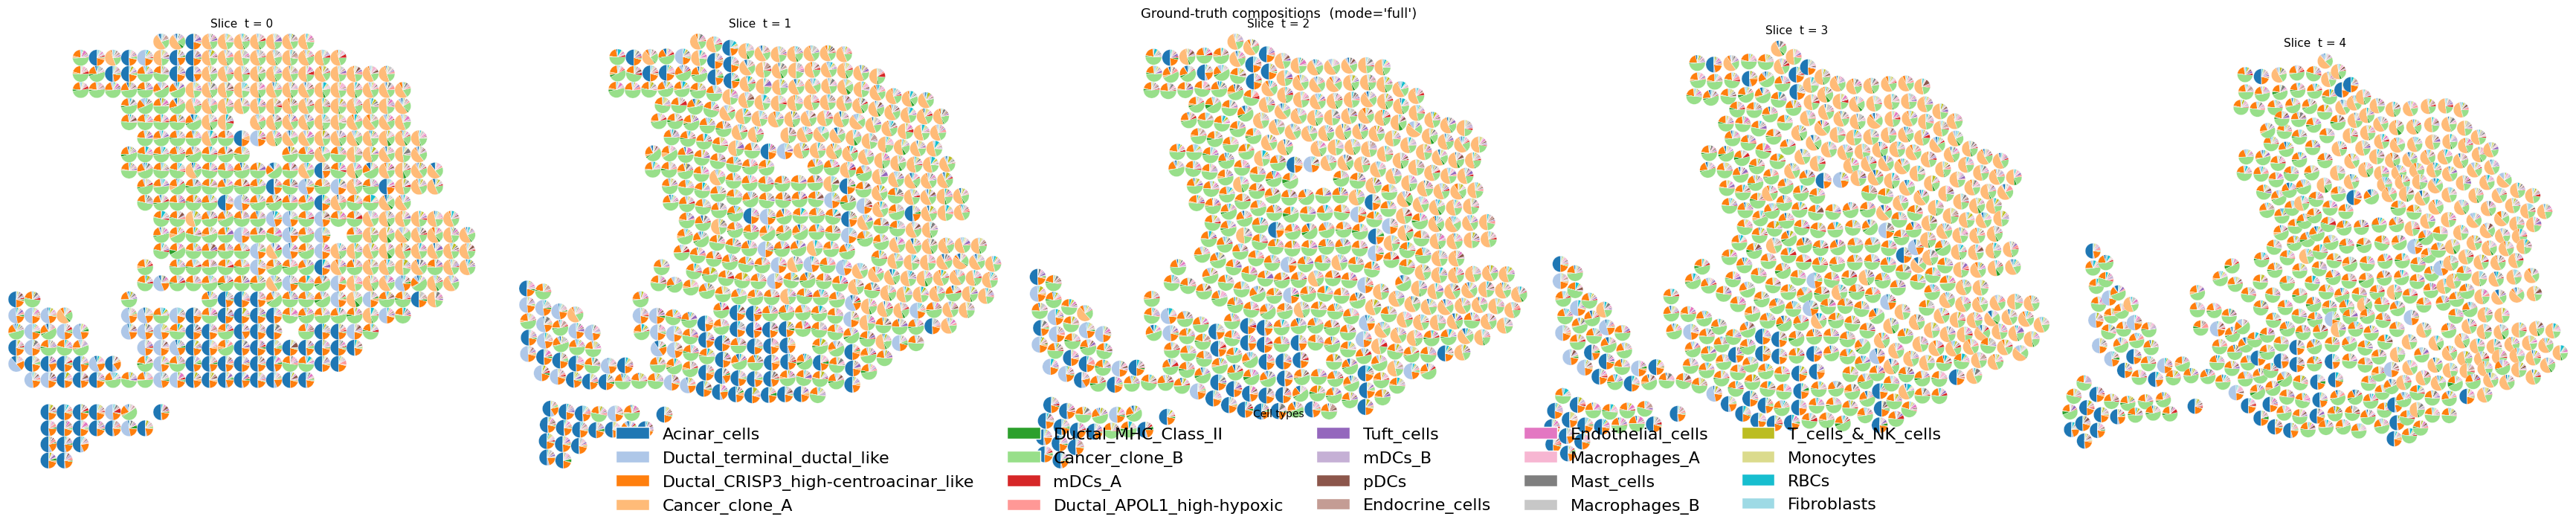

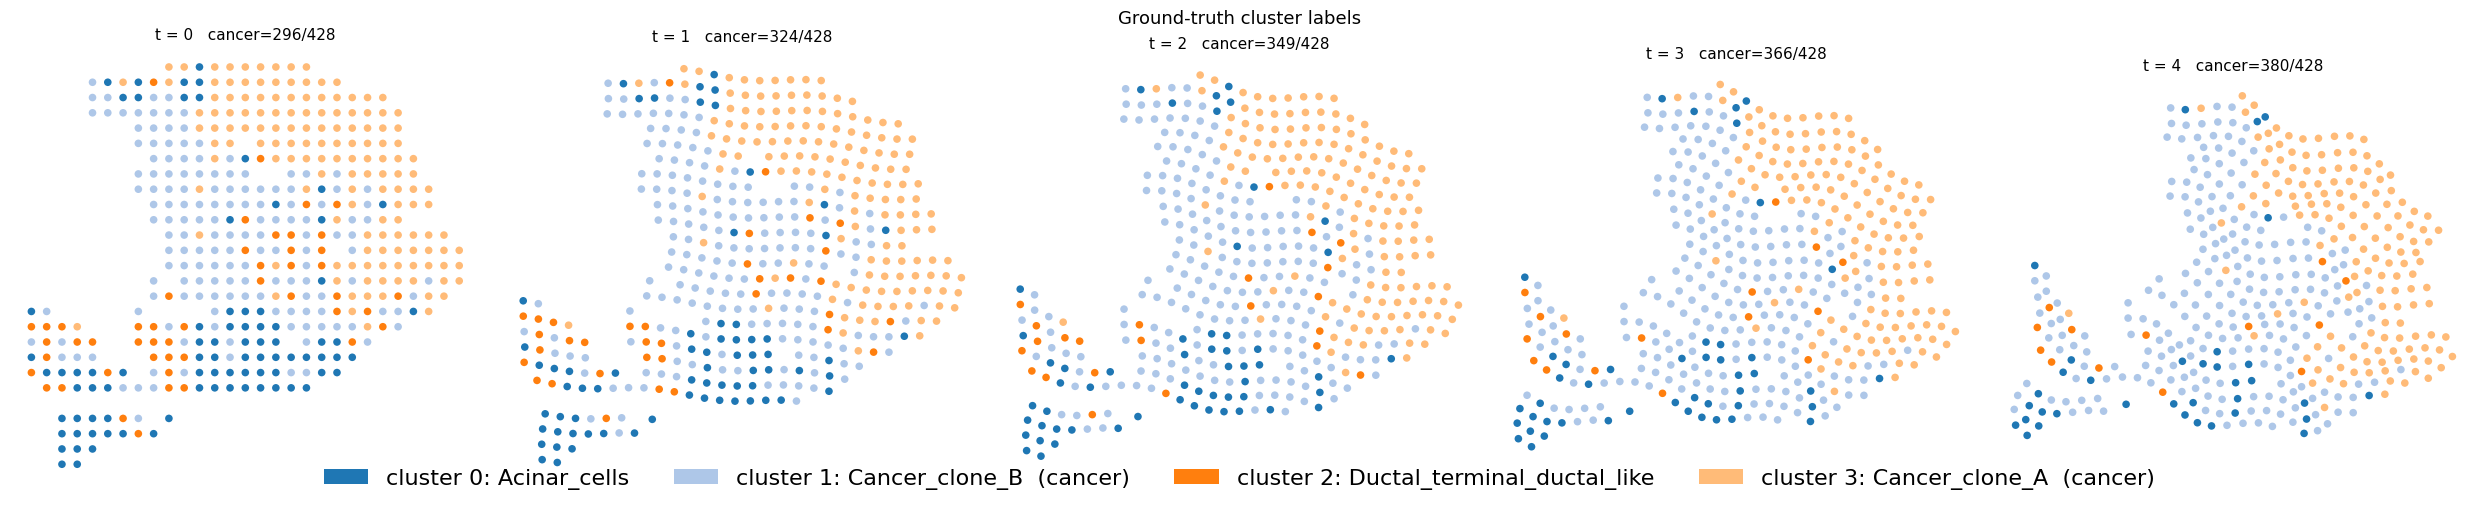

In [4]:
figs = visualize_all(
    adata_list      = adata_list,
    V_true_temporal = V_true_temporal,
    pd_B            = pd_B,
    warp_params     = warp_params,
    ref_adata       = adata,
    radius          = 0.5,   
    mode            = "full",
    view="both"
)
plt.show()

# Run ATLIS

In [5]:

V_est, pi, _ = solve_V_all_slices(
        adata_list,
        pd_B,
        lam=1e2,
        mu=1e2,
        k=10,
        step_rate="automatic",
        one_step=True,
    )


/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/objective.py:449: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adata_group, axis=0, join="outer")
/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/objective.py:452: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata_sub = adata[:, common].copy()


iter    0  f=5.546057e+06  rel_drop=9.031e-01  mean step=2.73e-05
iter   50  f=4.647459e+06  rel_drop=6.597e-05  mean step=1.97e-05
iter   99  f=4.641607e+06  rel_drop=9.997e-06  mean step=1.96e-05
stopped after iteration # 99
iter    0  f=6.348481e+06  rel_drop=8.893e-01  mean step=2.73e-05
iter   50  f=5.283991e+06  rel_drop=6.943e-05  mean step=1.93e-05
iter  100  f=5.276700e+06  rel_drop=1.024e-05  mean step=1.92e-05
iter  101  f=5.276648e+06  rel_drop=9.945e-06  mean step=1.92e-05
stopped after iteration # 101
iter    0  f=6.129170e+06  rel_drop=8.920e-01  mean step=2.73e-05
iter   50  f=5.093167e+06  rel_drop=6.775e-05  mean step=1.83e-05
iter   94  f=5.087055e+06  rel_drop=9.889e-06  mean step=1.83e-05
stopped after iteration # 94
iter    0  f=6.665240e+06  rel_drop=8.842e-01  mean step=2.73e-05
iter   50  f=5.488900e+06  rel_drop=7.244e-05  mean step=1.83e-05
iter   96  f=5.481724e+06  rel_drop=9.928e-06  mean step=1.83e-05
stopped after iteration # 96
iter    0  f=6.343599e+06

# Cluster and assign labels based on ATLIS scores

In [6]:

ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
    np.vstack(V_est),
    ad.concat(adata_list),
    celltype_key="cluster",
    embedding_key="spatial",
    clustering="leiden",
    n_clusters=4,
    n_neighbors=15,
    resolution=1.0,                
    auto_resolution=True,          
    resolution_grid=None,
    random_state=0,
    plot=False
)
n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_list])
for i, adt in enumerate(adata_list):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))

/tmp/ipykernel_373069/1523737387.py:3: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  ad.concat(adata_list),
/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:26: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(tmp, resolution=resolution, key_added=key, random_state=random_state)


/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:26: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(tmp, resolution=resolution, key_added=key, random_state=random_state)
/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:26: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s i

Leiden: target_k=4, best_resolution=0.159, n_clusters=4
ari=0.8970093014749726
nmi=0.8755188446063696


Text(0.5, 1.0, 'ATLIS')

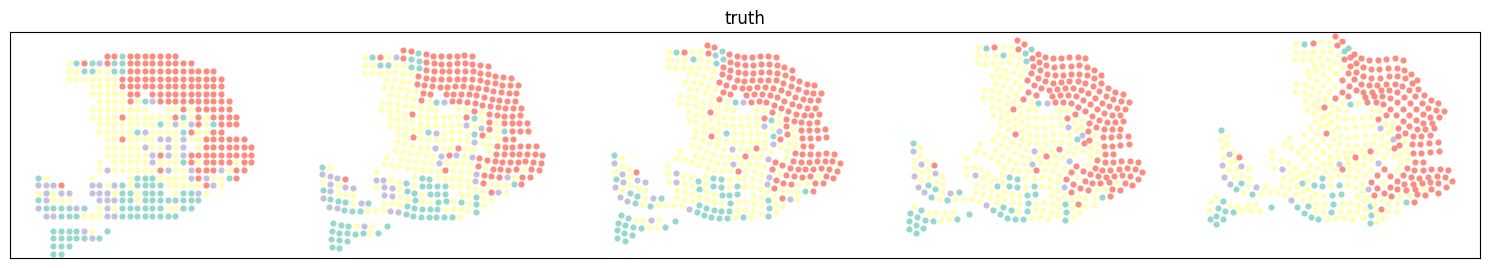

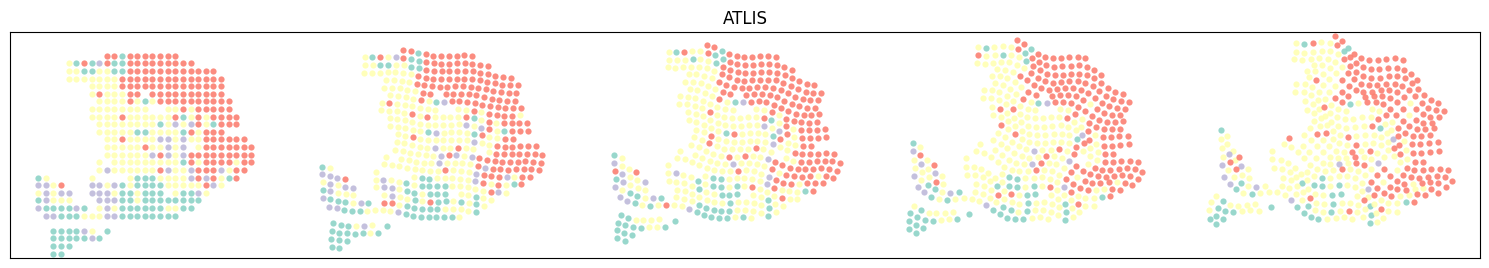

In [7]:
fig, ax = plot_slices_horizontal_centered(adata_list, 'cluster', x_gap=10, s=20, truth_key='cluster', legend=False)
ax.set_title('truth')

fig, ax = plot_slices_horizontal_centered(adata_list, 'pred_label', x_gap=10, s=20, truth_key='cluster', legend=False)
ax.set_title('ATLIS')


# Visualize OT coupling

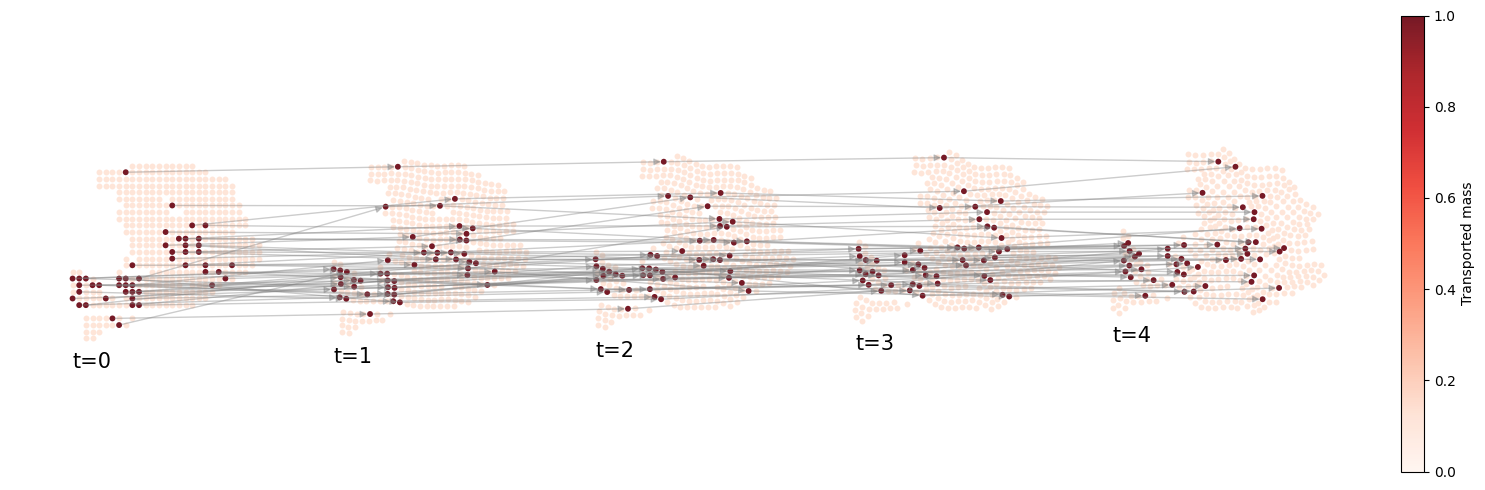

In [8]:
pi_dense = [p.toarray() if sp.issparse(p) else np.asarray(p) for p in pi]

fig, ax, _= plot_mass_transport_heatmap(
    adata_list,
    V_est,
    pi_dense,
    t_start=0,
    t_end=4, 
    source_celltype=2,
    celltype_obs_key="cluster",
    source_mass_source="obs",
    y_gap=40,
    y_scale=1,
    show_edges=True,
    n_sources_show = 100,
    alpha=0.9,
    edge_lw = 1.0,
    cmap="Reds",
    edge_alpha=0.4,
    background_color=plt.get_cmap("Reds")(0.1),
    figsize=(15,5),
    )

# Given scores at first/last slices, impute all intermediate ones

In [9]:
n_time = 5

def norm_rows(V):
    V = np.asarray(V)
    row_sum = V.sum(axis=1, keepdims=True)
    return V / np.where(row_sum == 0, 1.0, row_sum)

X1 = np.vstack([adata_list[-1].obs['x'], adata_list[-1].obs['y']]).T
X0 = np.vstack([adata_list[0].obs['x'],  adata_list[0].obs['y']]).T
Y1 = norm_rows(V_est[-1])
Y0 = norm_rows(V_est[0])

X_aligned_list = []
X_true_list    = []
Y_bar_list     = []
Y_true_list    = []


for i in range(3):
    X_bar, Y_bar, C_bar, log = impute_slice_fgw_barycenter(
        X0, Y0, X1, Y1,
        t=0.25 * (i + 1),
        N_bary=adata_list[i+1].obs['x'].shape[0],
        alpha=0.5,
        random_state=42,
    )
    X_true        = np.vstack([adata_list[i+1].obs['x'], adata_list[i+1].obs['y']]).T
    X_bar_aligned = align_by_pca(X_bar, X_true)

    X_aligned_list.append(X_bar_aligned)
    X_true_list.append(X_true)
    Y_bar_list.append(norm_rows(Y_bar))   # normalized
    Y_true_list.append(norm_rows(V_true_temporal[i+1]))

# Pick some marker genes to visualize

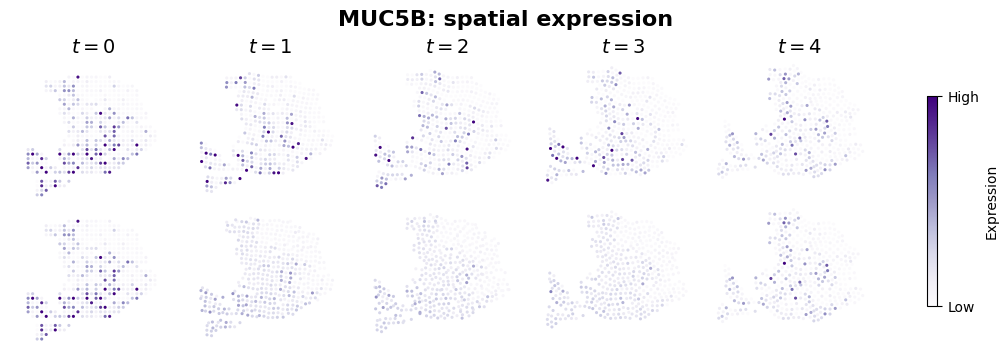

In [10]:
gene = 'MUC5B'
truth = [panel(a, gene) for a in adata_list]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="global", cmap='Purples')

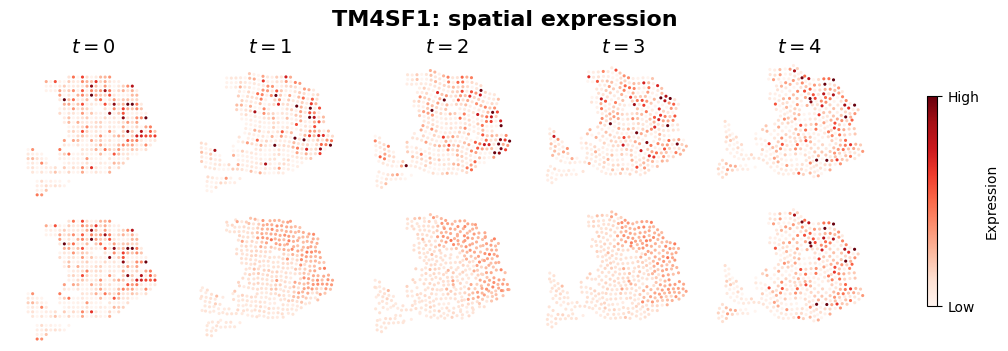

In [11]:
gene = 'TM4SF1'
truth = [panel(a, gene) for a in adata_list]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="global", cmap='Reds')